In [20]:
suppressMessages(library(DESeq2))
suppressMessages(library(ggplot2))
suppressMessages(library(sva))
library(ggrepel)

In [21]:
out_dir <- "../../results/11_compare_with_GSE294965/03_pca_by_deseq2"

if (!dir.exists(out_dir)) {
    dir.create(out_dir, recursive = TRUE)
}

In [22]:
df <- read.csv("../../results/11_compare_with_GSE294965/02_compare/counts_bulk.csv", 
row.names = 1)
df <- t(df)

In [23]:
dim(df)

[1] 470  37

In [24]:
coldata <- read.csv("../../results/11_compare_with_GSE294965/02_compare/meta_bulk.csv", row.names = 1)

In [25]:
head(coldata)

,SampleName,group,data
,<chr>,<chr>,<chr>
X1,sample.X1,Normal,Xenium
X10,sample.X10,Normal,Xenium
X15,sample.X15,LN,Xenium
X16,sample.X16,LN,Xenium
X2,sample.X2,Normal,Xenium
X22,sample.X22,LN,Xenium


In [26]:
dds <- DESeqDataSetFromMatrix(
  countData = df,
  colData = coldata,
  design = ~ data + group
)

converting counts to integer mode

Warning message in DESeqDataSet(se, design = design, ignoreRank):
“some variables in design formula are characters, converting to factors”


In [27]:
dds

class: DESeqDataSet 
dim: 470 37 
metadata(1): version
assays(1): counts
rownames(470): ABCC3 ABR ... ZEB2 ZNF683
rowData names(0):
colnames(37): X1 X10 ... sample_X1899 sample_X1912
colData names(3): SampleName group data

In [28]:
# optional but recommended: remove very low-count genes
keep <- rowSums(counts(dds) >= 10) >= 5
dds <- dds[keep, ]

# run DESeq pipeline
dds <- DESeq(dds)

# variance stabilizing transform
vsd <- varianceStabilizingTransformation(dds, blind = FALSE)

estimating size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

-- note: fitType='parametric', but the dispersion trend was not well captured by the
   function: y = a/x + b, and a local regression fit was automatically substituted.
   specify fitType='local' or 'mean' to avoid this message next time.

final dispersion estimates

fitting model and testing

-- replacing outliers and refitting for 1 genes
-- DESeq argument 'minReplicatesForReplace' = 7 
-- original counts are preserved in counts(dds)

estimating dispersions

fitting model and testing



In [29]:
vsd

class: DESeqTransform 
dim: 470 37 
metadata(1): version
assays(1): ''
rownames(470): ABCC3 ABR ... ZEB2 ZNF683
rowData names(31): baseMean baseVar ... maxCooks replace
colnames(37): X1 X10 ... sample_X1899 sample_X1912
colData names(5): SampleName group data sizeFactor replaceable

using ntop=400 top features by variance



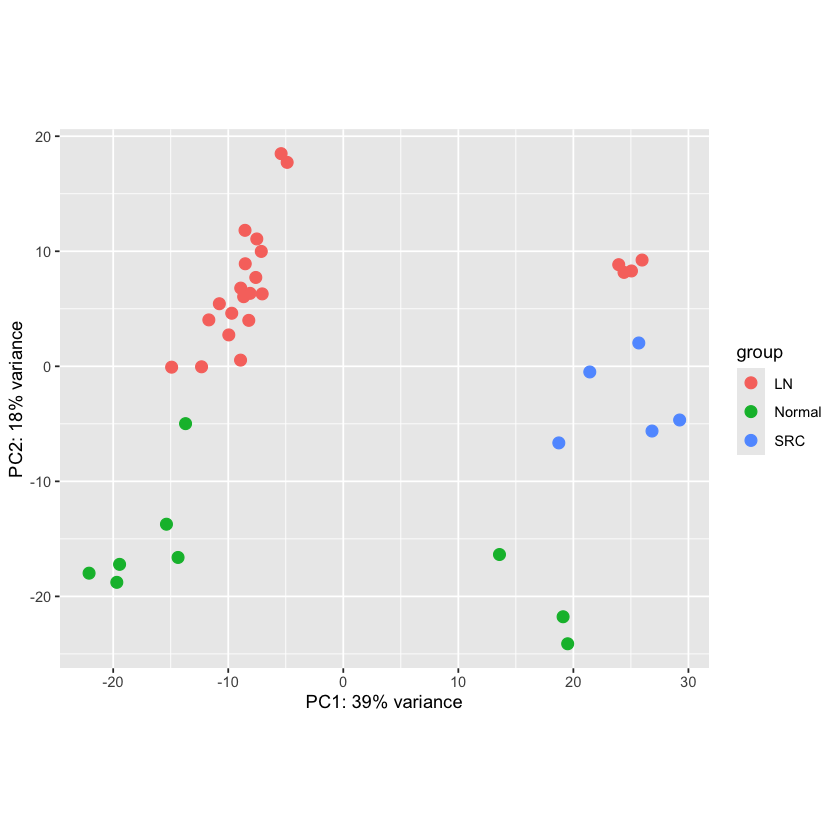

In [30]:
# quick PCA using DESeq2
plotPCA(vsd, ntop=400, intgroup = "group")

In [31]:
batch <- coldata$data
mod <- model.matrix(~ group, data = coldata)

In [32]:
mat <- assay(vsd)

Found2batches

Adjusting for2covariate(s) or covariate level(s)

Standardizing Data across genes

Fitting L/S model and finding priors

Finding parametric adjustments

Adjusting the Data




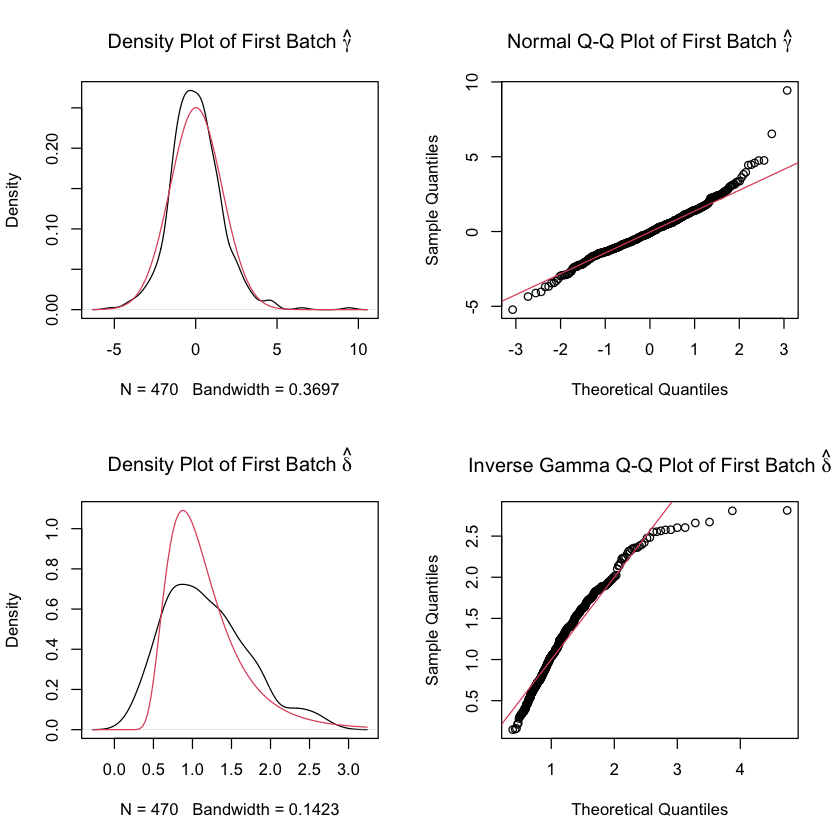

In [33]:
mat_combat <- ComBat(
  dat = mat,
  batch = batch,
  mod = mod,
  par.prior = TRUE,
  prior.plots = TRUE
)

In [34]:
# compute distance 
dist_mat <- dist(t(mat_combat))

In [35]:
dist_mat

                           X1      X10      X15      X16       X2      X22
X10                  26.34699                                             
X15                  29.47780 36.92786                                    
X16                  28.75325 33.88630 16.95505                           
X2                   28.15871 23.24152 33.45502 34.47818                  
X22                  28.41109 32.16169 18.78911 19.48201 31.85666         
X23                  36.58907 40.25738 25.87531 25.65851 37.76732 24.44304
X24                  31.04348 39.23955 17.25826 21.55837 38.43439 16.60041
X30                  29.12121 37.32742 14.31685 16.01365 36.38771 16.38821
X31                  30.55582 36.57884 14.19671 17.91788 32.64084 16.90982
X32                  31.66353 39.16097 14.43326 22.61003 32.02601 20.13024
X39                  25.19189 34.12860 17.41624 13.30142 33.84074 16.93871
X40                  28.94265 30.54842 17.82018 19.69373 28.71793 17.75540
X41                  31.3

In [36]:
pca <- prcomp(t(mat_combat), scale. = TRUE)

In [37]:
pca_df <- as.data.frame(pca$x[, 1:5])
pca_df$sample <- rownames(pca_df)
pca_df$condition <- coldata[rownames(pca_df), "group"]
pca_df$batch <- coldata[rownames(pca_df), "data"]

percentVar <- (pca$sdev^2 / sum(pca$sdev^2))[1:2] * 100

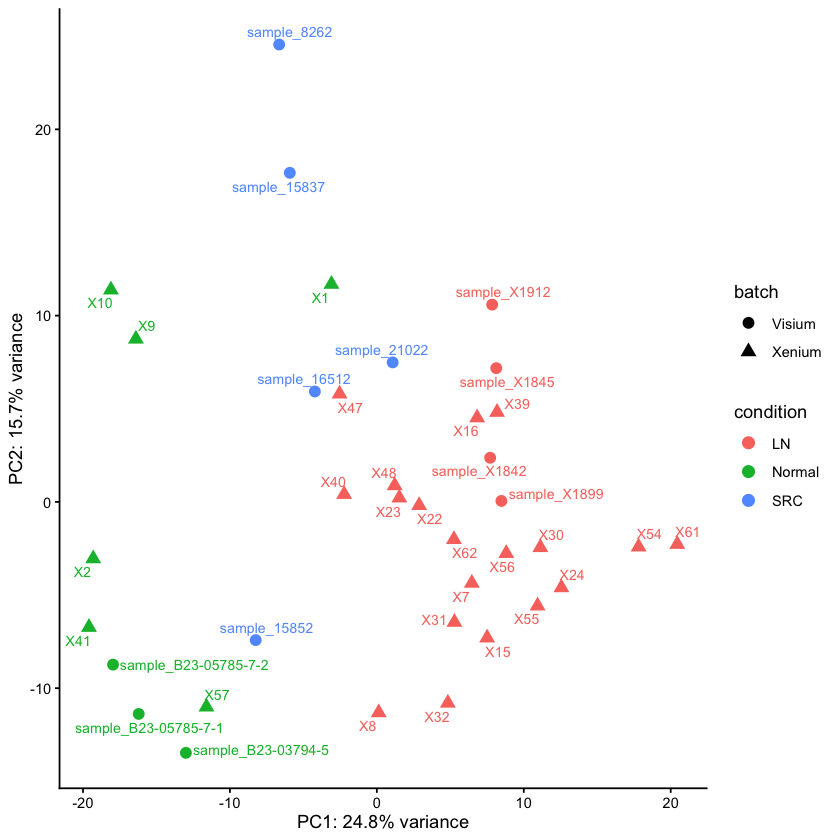

In [38]:
ggplot(pca_df, aes(PC1, PC2, color = condition, 
shape = batch, label = sample)) +
  geom_point(size = 3) +
  geom_text_repel(size = 3) +
  xlab(sprintf("PC1: %.1f%% variance", percentVar[1])) +
  ylab(sprintf("PC2: %.1f%% variance", percentVar[2])) +
  theme_classic()

In [39]:
write.csv(pca_df, glue::glue("{out_dir}/pca_df.csv"), 
row.names = TRUE, quote = FALSE)